<a href="https://colab.research.google.com/github/ayandeshmukh75-hue/Car-Price-Prediction-with-Machine-Learning/blob/main/Car_Price_Prediction_with_Machine_Learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:

from google.colab import files

uploaded = files.upload()

filename = next(iter(uploaded))
df = pd.read_csv(filename)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Saving car data.csv to car data (1).csv
Dataset loaded successfully!
Dataset shape: (301, 9)


,Car_Name,Year,Selling_Price,Present_Price,Driven_kms,Fuel_Type,Selling_type,Transmission,Owner
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0


In [3]:

print("Column Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nStatistical Summary:")
display(df.describe(include="all"))

Column Names:
['Car_Name', 'Year', 'Selling_Price', 'Present_Price', 'Driven_kms', 'Fuel_Type', 'Selling_type', 'Transmission', 'Owner']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 301 entries, 0 to 300
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Car_Name       301 non-null    object 
 1   Year           301 non-null    int64  
 2   Selling_Price  301 non-null    float64
 3   Present_Price  301 non-null    float64
 4   Driven_kms     301 non-null    int64  
 5   Fuel_Type      301 non-null    object 
 6   Selling_type   301 non-null    object 
 7   Transmission   301 non-null    object 
 8   Owner          301 non-null    int64  
dtypes: float64(2), int64(3), object(4)
memory usage: 21.3+ KB

Missing Values:
Car_Name         0
Year             0
Selling_Price    0
Present_Price    0
Driven_kms       0
Fuel_Type        0
Selling_type     0
Transmission     0
Owner            0
dt

,Car_Name,Year,Selling_Price,Present_Price,Driven_kms,Fuel_Type,Selling_type,Transmission,Owner
count,301,301.000000,301.000000,301.000000,301.000000,301,301,301,301.000000
unique,98,NaN,NaN,NaN,NaN,3,2,2,NaN
top,city,NaN,NaN,NaN,NaN,Petrol,Dealer,Manual,NaN
freq,26,NaN,NaN,NaN,NaN,239,195,261,NaN
mean,NaN,2013.627907,4.661296,7.628472,36947.205980,NaN,NaN,NaN,0.043189
std,NaN,2.891554,5.082812,8.642584,38886.883882,NaN,NaN,NaN,0.247915
min,NaN,2003.000000,0.100000,0.320000,500.000000,NaN,NaN,NaN,0.000000
25%,NaN,2012.000000,0.900000,1.200000,15000.000000,NaN,NaN,NaN,0.000000
50%,NaN,2014.000000,3.600000,6.400000,32000.000000,NaN,NaN,NaN,0.000000
75%,NaN,2016.000000,6.000000,9.900000,48767.000000,NaN,NaN,NaN,0.000000


In [4]:

df_clean = df.copy()

# Remove duplicate rows, if any
df_clean = df_clean.drop_duplicates().copy()

# Check important numeric columns
numeric_cols = [
    "Year",
    "Selling_Price",
    "Present_Price",
    "Driven_kms",
    "Owner"
]

for col in numeric_cols:
    df_clean[col] = pd.to_numeric(df_clean[col], errors="coerce")

# Remove rows with missing target values
df_clean = df_clean.dropna(subset=["Selling_Price"])

print("Original rows:", len(df))
print("Rows after cleaning:", len(df_clean))
print("Missing values after cleaning:")
print(df_clean.isnull().sum())

Original rows: 301
Rows after cleaning: 299
Missing values after cleaning:
Car_Name         0
Year             0
Selling_Price    0
Present_Price    0
Driven_kms       0
Fuel_Type        0
Selling_type     0
Transmission     0
Owner            0
dtype: int64


In [5]:

# Use the latest year present in the dataset as a consistent reference
reference_year = int(df_clean["Year"].max())

df_clean["Car_Age"] = reference_year - df_clean["Year"]

print("Reference year:", reference_year)
print("New feature 'Car_Age' created successfully!")

display(
    df_clean[
        ["Car_Name", "Year", "Car_Age",
         "Present_Price", "Driven_kms", "Selling_Price"]
    ].head()
)

Reference year: 2018
New feature 'Car_Age' created successfully!


,Car_Name,Year,Car_Age,Present_Price,Driven_kms,Selling_Price
0,ritz,2014,4,5.59,27000,3.35
1,sx4,2013,5,9.54,43000,4.75
2,ciaz,2017,1,9.85,6900,7.25
3,wagon r,2011,7,4.15,5200,2.85
4,swift,2014,4,6.87,42450,4.60


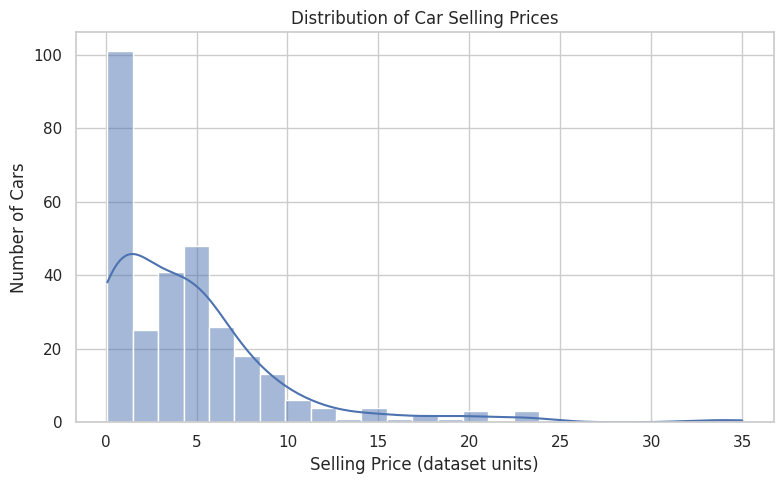

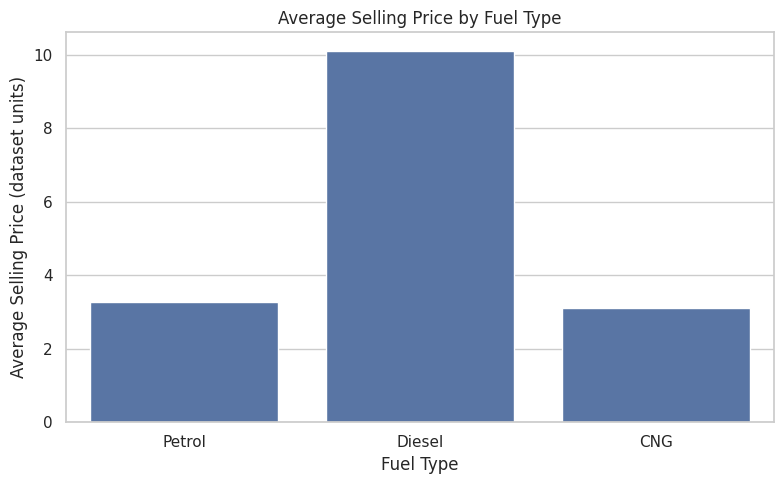

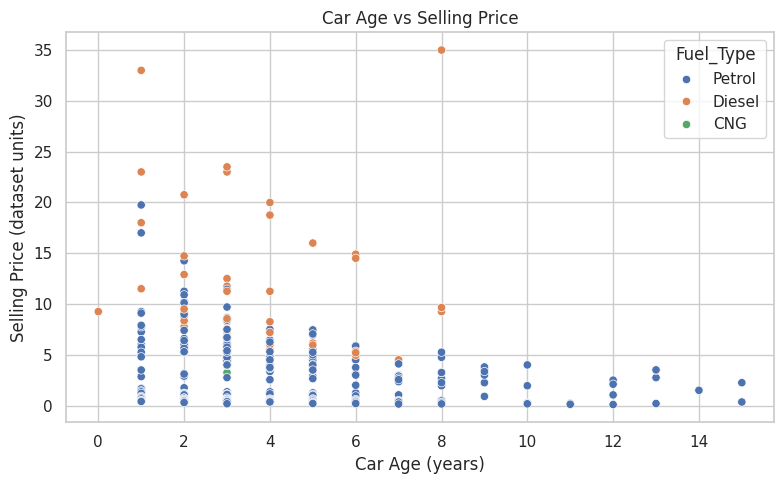

In [6]:

# Graph 1: Selling Price Distribution
plt.figure(figsize=(8, 5))
sns.histplot(data=df_clean, x="Selling_Price", bins=25, kde=True)
plt.title("Distribution of Car Selling Prices")
plt.xlabel("Selling Price (dataset units)")
plt.ylabel("Number of Cars")
plt.tight_layout()
plt.savefig("selling_price_distribution.png", dpi=300)
plt.show()

# Graph 2: Average Selling Price by Fuel Type
plt.figure(figsize=(8, 5))
sns.barplot(
    data=df_clean,
    x="Fuel_Type",
    y="Selling_Price",
    errorbar=None
)
plt.title("Average Selling Price by Fuel Type")
plt.xlabel("Fuel Type")
plt.ylabel("Average Selling Price (dataset units)")
plt.tight_layout()
plt.savefig("fuel_type_comparison.png", dpi=300)
plt.show()

# Graph 3: Car Age vs Selling Price
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df_clean,
    x="Car_Age",
    y="Selling_Price",
    hue="Fuel_Type"
)
plt.title("Car Age vs Selling Price")
plt.xlabel("Car Age (years)")
plt.ylabel("Selling Price (dataset units)")
plt.tight_layout()
plt.savefig("car_age_vs_price.png", dpi=300)
plt.show()

In [8]:

# Features used for prediction
feature_cols = [
    "Car_Name",
    "Year",
    "Car_Age",
    "Present_Price",
    "Driven_kms",
    "Fuel_Type",
    "Selling_type",
    "Transmission",
    "Owner"
]

X = df_clean[feature_cols]
y = df_clean["Selling_Price"]

categorical_features = [
    "Car_Name",
    "Fuel_Type",
    "Selling_type",
    "Transmission"
]

numeric_features = [
    "Year",
    "Car_Age",
    "Present_Price",
    "Driven_kms",
    "Owner"
]

print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("\nTarget variable: Selling_Price")

Features shape: (299, 9)
Target shape: (299,)

Target variable: Selling_Price


In [10]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 239
Testing records: 60


In [12]:

# Prepare categorical and numerical columns
preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            Pipeline(steps=[
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("encoder", OneHotEncoder(handle_unknown="ignore"))
            ]),
            categorical_features
        ),
        (
            "numerical",
            Pipeline(steps=[
                ("imputer", SimpleImputer(strategy="median"))
            ]),
            numeric_features
        )
    ]
)

# Create the regression pipeline
model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=200,
        random_state=42
    ))
])

# Train the model
model.fit(X_train, y_train)

print("Model training completed successfully!")

Model training completed successfully!


In [13]:

# Predict prices for test data
y_pred = model.predict(X_test)

# Calculate evaluation metrics
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("MODEL EVALUATION")
print("-" * 30)
print(f"MAE  : {mae:.3f}")
print(f"RMSE : {rmse:.3f}")
print(f"R² Score: {r2:.3f}")
print(f"R² Percentage: {r2 * 100:.2f}%")

MODEL EVALUATION
------------------------------
MAE  : 1.434
RMSE : 3.507
R² Score: 0.523
R² Percentage: 52.27%


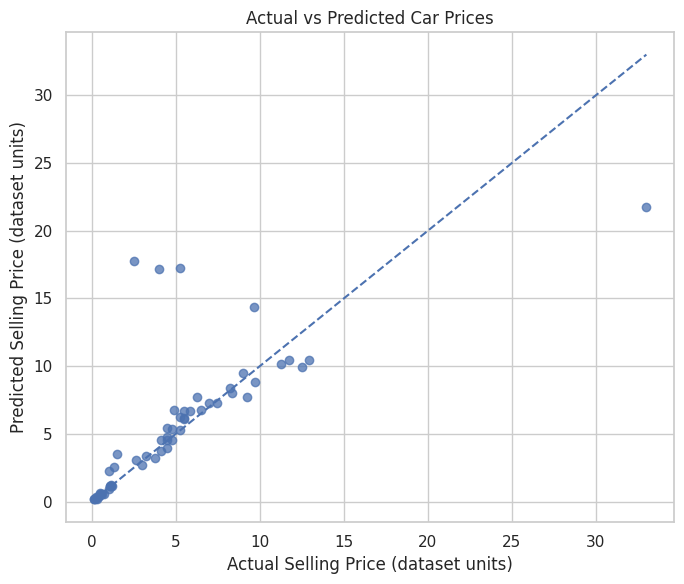

,Actual Price,Predicted Price
0,8.99,9.49620
1,8.35,7.98380
2,0.45,0.44110
3,7.45,7.27625
4,5.25,17.25970
5,5.25,5.30850
6,5.85,6.72105
7,1.15,1.18975
8,9.25,7.73105
9,0.38,0.30555


In [14]:

plt.figure(figsize=(7, 6))

plt.scatter(y_test, y_pred, alpha=0.75)

# Reference line for perfect predictions
low = min(y_test.min(), y_pred.min())
high = max(y_test.max(), y_pred.max())

plt.plot([low, high], [low, high], linestyle="--")

plt.title("Actual vs Predicted Car Prices")
plt.xlabel("Actual Selling Price (dataset units)")
plt.ylabel("Predicted Selling Price (dataset units)")
plt.tight_layout()
plt.savefig("actual_vs_predicted.png", dpi=300)
plt.show()

# Compare a few actual and predicted values
comparison = pd.DataFrame({
    "Actual Price": y_test.to_numpy(),
    "Predicted Price": y_pred
})

display(comparison.head(10))

In [15]:

# Example car details
new_car = pd.DataFrame([{
    "Car_Name": "swift",
    "Year": 2018,
    "Car_Age": reference_year - 2018,
    "Present_Price": 6.0,
    "Driven_kms": 30000,
    "Fuel_Type": "Petrol",
    "Selling_type": "Dealer",
    "Transmission": "Manual",
    "Owner": 0
}])

predicted_price = model.predict(new_car)[0]

print("NEW CAR DETAILS")
display(new_car)

print(f"Estimated Selling Price: {predicted_price:.2f}")
print("Note: Prediction is in the same price units as the dataset.")

NEW CAR DETAILS


,Car_Name,Year,Car_Age,Present_Price,Driven_kms,Fuel_Type,Selling_type,Transmission,Owner
0,swift,2018,0,6.0,30000,Petrol,Dealer,Manual,0


Estimated Selling Price: 5.13
Note: Prediction is in the same price units as the dataset.


In [17]:

import os
import zipfile
from google.colab import files

graph_files = [
    "selling_price_distribution.png",
    "fuel_type_comparison.png",
    "car_age_vs_price.png",
    "actual_vs_predicted.png"
]

with zipfile.ZipFile("car_price_graphs.zip", "w") as zip_file:
    for graph in graph_files:
        if os.path.exists(graph):
            zip_file.write(graph)

files.download("car_price_graphs.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>